# UCB1

Upper confidence bounds add an exploration bonus to each empirical mean. Arms with few pulls receive a larger bonus.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Choose an arm

The decision rule has access only to earlier pulls and rewards.

In [2]:
import numpy as np
import matplotlib.pyplot as plt


def select(count, wins, t, rng):
    untried = np.flatnonzero(count == 0)
    if len(untried):
        return int(untried[0])
    return int(np.argmax(wins / count + np.sqrt(2 * np.log(t + 1) / count)))

## A thousand decisions

Each of 80 independent runs starts from zero observations. Expected pseudo-regret uses the known generating means.

Mean reward 0.585 | Best-arm pull rate 46.7%
Final mean pseudo-regret 75.30 | Monte Carlo SE 0.92
Uniform-policy expected pseudo-regret: 146.00


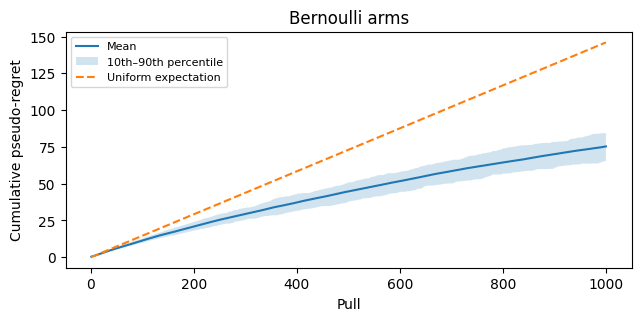

In [3]:
prob = np.array([0.32, 0.48, 0.53, 0.66, 0.58])
horizon = 1000
regrets = []
rewards = []
optimal = []
for seed in range(170, 250):
    rng = np.random.default_rng(seed)
    count = np.zeros(len(prob))
    wins = np.zeros(len(prob))
    gaps = []
    earned = []
    for t in range(horizon):
        arm = select(count, wins, t, rng)
        reward = float(rng.random() < prob[arm])
        count[arm] += 1
        wins[arm] += reward
        earned.append(reward)
        gaps.append(prob.max() - prob[arm])
    regrets.append(np.cumsum(gaps))
    rewards.append(np.mean(earned))
    optimal.append(count[prob.argmax()] / horizon)
regrets = np.asarray(regrets)
print(f"Mean reward {np.mean(rewards):.3f} | Best-arm pull rate {np.mean(optimal):.1%}")
print(
    f"Final mean pseudo-regret {regrets[:,-1].mean():.2f} | Monte Carlo SE {regrets[:,-1].std(ddof=1)/np.sqrt(len(regrets)):.2f}"
)
print(f"Uniform-policy expected pseudo-regret: {horizon*(prob.max()-prob.mean()):.2f}")
fig, ax = plt.subplots(figsize=(6.3, 3.1), constrained_layout=True)
time = np.arange(1, horizon + 1)
ax.plot(time, regrets.mean(0), label="Mean")
lo, hi = np.quantile(regrets, [0.1, 0.9], axis=0)
ax.fill_between(time, lo, hi, alpha=0.2, label="10th–90th percentile")
ax.plot(time, time * (prob.max() - prob.mean()), "--", label="Uniform expectation")
ax.set(xlabel="Pull", ylabel="Cumulative pseudo-regret", title="Bernoulli arms")
ax.legend(fontsize=8)
plt.show()

## Reading the result

The shaded region describes variation between runs. Regret compares expected rewards and does not count a lucky draw from a weak arm as an optimal decision.

## References

[Sutton and Barto, Reinforcement Learning: An Introduction (2018)](https://mitpress.mit.edu/9780262039246/reinforcement-learning/)

[Auer, Cesa-Bianchi and Fischer, Finite-time Analysis of the Multiarmed Bandit Problem (2002)](https://doi.org/10.1023/A:1013689704352)